In [1]:
from tqdm import tqdm
from astropy.table import Table
import numpy as np
import h5py
import pandas as pd
import data
import matplotlib.pyplot as plt
import sample
import halotools
from scipy import stats
from multicam.multicam import MultiCAM
from multicam.multicam import MultiCamSampling
import pickle

TNG_H = 0.6774
COLOR_CUT = 0.85

In [2]:
## Load data ###
hydro_full = pd.read_csv(
    'data/cache_files/hydro_color_tree_subhaloflag_check_data.csv',
    usecols=[
        'SubhaloMass', 'StellarMass', 'x', 'y', 'z',
        'logStellarMass', 'logSubhaloMass', 'g-i',
        'vpeak', 'a12', 'mpeak',
        *[f'mpeak_mah{ii}' for ii in range(100)]
    ]
)

print("\nHydro Table")
print(len(hydro_full))

print("\nCache files read in!")

# 1.4 * 10^8 minimum on Stellar Mass for hydro catalog
hydro_full = hydro_full[hydro_full['StellarMass'] >= (1.4 * 10**8 * TNG_H)] 
print("\nNew Hydro Table Length:")
print(len(hydro_full))

# Add z12 column to dmo_full
hydro_full['z12'] = (1 / hydro_full['a12']) - 1
print(hydro_full)


Hydro Table
101364

Cache files read in!

New Hydro Table Length:
29365
         SubhaloMass   StellarMass          x          y          z  \
0       2.747794e+14  1.638342e+12   0.849091  26.326996  18.306934   
1       3.666623e+13  2.573102e+11   0.106473  24.633322  16.900553   
2       7.734555e+12  2.885268e+11   0.853112  26.725748  17.510680   
3       3.253667e+12  6.276475e+10   0.768784  26.518290  15.530523   
4       2.980181e+12  8.770330e+10   1.426592  26.341442  19.041204   
...              ...           ...        ...        ...        ...   
101074  2.264540e+09  1.073404e+08  45.610706  37.350147  71.114685   
101087  2.725294e+09  1.011815e+08  39.784622  22.906060  48.659190   
101095  1.864903e+09  1.329762e+08   2.695573  17.533588  24.069653   
101176  1.199852e+09  1.216635e+08  40.577625  66.834870  41.010323   
101187  1.858363e+09  9.611342e+07  14.283656  63.483150  72.761600   

        logSubhaloMass  logStellarMass       vpeak       a12         mpeak

In [25]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set global font size for all text elements (optional, can be overridden)
mpl.rcParams['font.size'] = 20

# Set global font size for axis labels
mpl.rcParams['axes.labelsize'] = 30

# Set global font size for tick numbers
mpl.rcParams['xtick.labelsize'] = 20
mpl.rcParams['ytick.labelsize'] = 20

# Set tick widths and sizes globally
mpl.rcParams['xtick.major.width'] = 3
mpl.rcParams['ytick.major.width'] = 3
mpl.rcParams['xtick.minor.width'] = 3
mpl.rcParams['ytick.minor.width'] = 3

mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['ytick.major.size'] = 5

# Set axes line width globally
mpl.rcParams['axes.linewidth'] = 3 # Sets the width of the spines

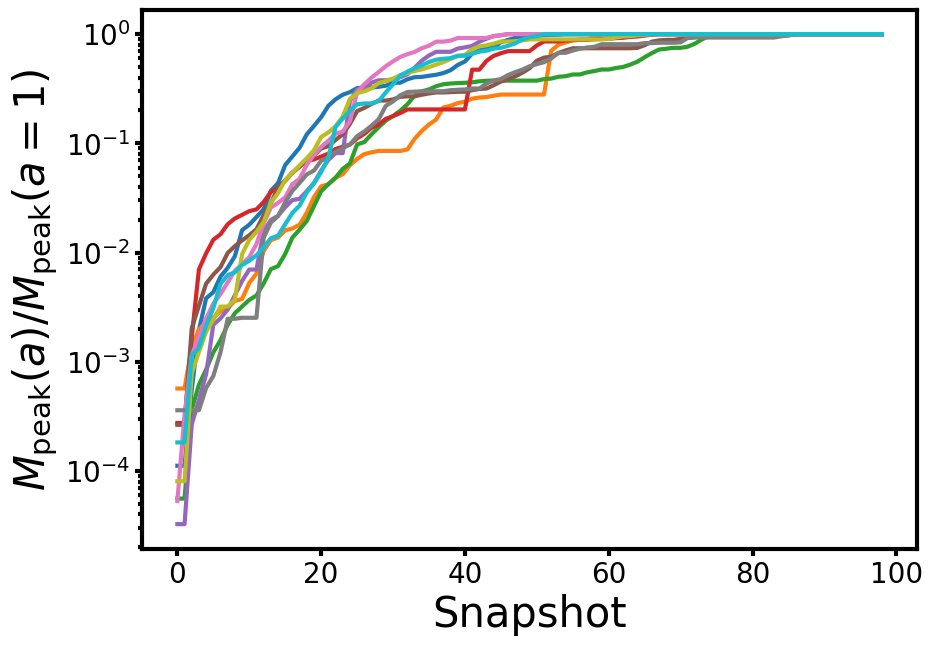

In [26]:
plt.figure(figsize=(10, 7))
ii_vals = range(0, 99)

for idx in range(10, 20):
    m_norm = [
        hydro_full.loc[idx, f'mpeak_mah{ii}']
        for ii in ii_vals
    ]
    plt.plot(ii_vals, m_norm, linewidth = 3)

plt.xlabel('Snapshot')
plt.yscale('log')
plt.ylabel(r'$M_{\rm peak}(a) / M_{\rm peak}(a=1)$')
# plt.show()
plt.savefig('mah.png', bbox_inches='tight', dpi=300)